# Job 51656823 — does the N=48 minimum survive at N=96?

Every "smallest architecture that still learns direct deduction" result in this
programme was measured at **N=48**. The standing minimum is attention-only
`L=16 d192` — no per-layer MLP, 2,504,890 trainable, `rho_50` 0.580 over 3/3
seeds (finding 53). Stage F asks the only question that decides whether any of
that generalizes: **does the same cut still reach the complete model when the
problem doubles?**

The test is a PAIRED comparison at N=96, both arms on the identical
14 × 400-instance leak-free grid (`--shuffle-adj --fall`) at the identical
240k × 50 budget:

| arm | architecture | trainable (predicted) | total |
|---|---|---|---|
| stripped | attention-only `L=16 d192` | 2,618,602 | 8,929,514 |
| control | full `L=12 d256` | — | 9,790,058 |

It is only 4 cells because the control mostly already exists: eight N=96 cells
have trained leak-free at this budget on this grid, and `full L=12 d256` came in
at `rho_50` **0.621** over two seeds. Stage F buys the stripped arm at three
seeds plus **the missing THIRD control seed**, which is what turns a two-draw
control into a quotable level.

**The registered predictions, from `scripts/stagef_score.py`, committed while
`51656823` was still training and before either arm had an N=96 eval on disk:**

* **F1 — it trains at all.** 3 of 3 stripped seeds produce a MEASURED `rho_50`
  on a grid whose floor is 0.32. **F1 gates F0**, because an unmeasured `rho_50`
  cannot be compared to a level. It also gates the READING of a censor: three
  censors is an architecture statement, one or two is finding 51's seed story.
* **F0 — the headline.** `|stripped − control| ≤ s*_96 = 0.119`. Both
  falsification directions were given a reading in advance, which is what stops
  either from being re-narrated afterwards: **HIGHER** by more than `s*_96` means
  the cut is load-bearing at N=96 and every minimum in this programme gets
  relabelled an N=48 claim; **LOWER** by more than `s*_96` reads as an
  undertrained control, not as the stripped arm winning.
* **F2 — the control is not one draw.** The third control seed lands inside
  `[0.564, 0.679]` AND the 3-seed median stays within `s*_96` of the 2-seed
  0.621. If F2 falsifies, F0 survives only as an ORDERING and the levels are not
  quotable.
* **F3 — the N=48 standing minimum does not move on N=96 evidence.** A
  registration, not a measurement. Stage F can CORROBORATE or UNDERMINE the
  N=48 minimum; it can never replace it.

Section 2 prints which branch the data landed in. Section 5 runs the registered
scorer verbatim. This notebook runs the scorer; it does not restate its
conclusions in its own words.

In [1]:
import json, os, subprocess, sys
sys.path.insert(0, "/home/users/hshunt/spin_gnn")
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

REPO = "/home/users/hshunt/spin_gnn"
BOOT = 2000          # the programme's scoring default; CIs here match the scorers'
SEEDS = (0, 1, 2)    # the stripped arm is 3 seeds; the control reaches 3 with this job

from scripts.stagef_score import (CONTROL, CONTROL_2SEED, CONTROL_BRACKET,
                                  CONTROL_NLL_BAND, CONTROL_TOTAL, GRID_FLOOR_96,
                                  N48_HUB, N48_MINIMUM, PREDICTED_TOTAL_96,
                                  PREDICTED_TRAINABLE_96, S48, S96, S96_PARTS,
                                  SCAN_F, SCAN_F_DIRS, STRIPPED, rho_txt)
from notebooks.make_stagef_deck import (collect96, gap, pair, title_for,
                                        verdict_f0, verdict_f1, verdict_f2)
from notebooks.make_stagehi_deck import acc_of, curve

COMMIT = subprocess.run(["git", "rev-parse", "--short", "HEAD"], cwd=REPO,
                        capture_output=True, text=True).stdout.strip()
print("git commit        ", COMMIT)
print("branch            ", subprocess.run(["git", "rev-parse", "--abbrev-ref", "HEAD"],
                                           cwd=REPO, capture_output=True,
                                           text=True).stdout.strip())
print("scorer registered ", "while 51656823 was still training")
print("deck registered   ", "2b78a9c, same -- no F cell had an eval on disk")
print("bootstrap draws   ", BOOT)
print("seeds per arm     ", SEEDS)
print("frozen yardstick  ", f"s*_96 = {S96} in rho_50, from "
                            + ", ".join(f"{k} {v}" for k, v in S96_PARTS.items()))
print("control at reg.   ", f"{CONTROL_2SEED} over 2 seeds, bracket "
                            f"[{CONTROL_BRACKET[0]:.3f}, {CONTROL_BRACKET[1]:.3f}]")
print("NLL band          ", f"{CONTROL_NLL_BAND[0]:.4f}-{CONTROL_NLL_BAND[1]:.4f}, "
                            "every leak-free N=96 cell to date")
print("grid floor        ", f"rho {GRID_FLOOR_96} at N=96 (N=48's is 0.33 -- never pooled)")
print("scan dirs         ", len(SCAN_F_DIRS), "dirs; the subject is",
      os.path.basename(SCAN_F))
print()
print("NOT USED HERE, and both are deliberate:")
print(f"  s* = {S48} is an N=48 number. It appears in this notebook only in "
      "this line.")
print("  finding 44's train NLL 1.64 is an N=48 plateau. N=96's plateau has never")
print("  been measured, so NO escape count is quoted and training is read against")
print("  the measured band above instead.")

git commit         fb2029c
branch             sudoku-dd
scorer registered  while 51656823 was still training
deck registered    2b78a9c, same -- no F cell had an eval on disk
bootstrap draws    2000
seeds per arm      (0, 1, 2)
frozen yardstick   s*_96 = 0.119 in rho_50, from L=12 fall 0.115, L=8 fall 0.138, L=12 cosine 0.104
control at reg.    0.621 over 2 seeds, bracket [0.564, 0.679]
NLL band           1.7456-1.8320, every leak-free N=96 cell to date
grid floor         rho 0.32 at N=96 (N=48's is 0.33 -- never pooled)
scan dirs          3 dirs; the subject is sudoku_n96_minarch_F_2026-11-09

NOT USED HERE, and both are deliberate:
  s* = 0.1484 is an N=48 number. It appears in this notebook only in this line.
  finding 44's train NLL 1.64 is an N=48 plateau. N=96's plateau has never
  been measured, so NO escape count is quoted and training is read against
  the measured band above instead.


## 2. The headline, selected by the branch the data fell in

The nine F1/F0/F2 branches below were named in `stagef_score.py` and in
`make_stagef_deck.py` before the run closed. The cell picks one; it does not
compose a sentence. The same `verdict_f1` / `verdict_f0` / `verdict_f2` helpers
drive the slides, so the deck and this page cannot disagree about which outcome
happened.

In [2]:
cells, raw = collect96(SCAN_F_DIRS, BOOT)
p = pair(cells)
st = p["stripped"]["s"] if p["stripped"] else None
ct = p["control"]["s"] if p["control"] else None
f1 = verdict_f1(st)
f0 = verdict_f0(st, ct, f1)
f2 = verdict_f2(ct)

print(f"{len(cells)} leak-free N=96 cells on disk | "
      f"F1 {f1.upper()} | F0 {f0.upper()} | F2 {f2.upper()}")
print()
print("  " + title_for(f1, f0))
print()
print(f"  {'arm':<34}{'rho_50':>10}{'mean_solve':>12}{'cross':>8}{'trainable':>12}")
print("  " + "-" * 76)
for tag in ("stripped", "control"):
    a = p[tag]
    if a is None:
        print(f"  {tag + '  (absent)':<34}{'--':>10}{'--':>12}{'--':>8}{'--':>12}")
        continue
    s = a["s"]
    print(f"  {tag + '  ' + a['name']:<34}{rho_txt(s):>10}{s['mean_solve']:>12.3f}"
          f"{str(s['n_cross']) + '/' + str(s['n']):>8}{a['trainable']:>12,}")
d = gap(st, ct)
print()
if d is None:
    print("  gap: n/a -- one side has no measured level, so F0 is not scored as a")
    print("  level at all. F1's reading is the result; see section 5.")
else:
    print(f"  gap: {d:+.3f} = {abs(d) / S96:.2f} s*_96, "
          f"{'INSIDE' if abs(d) <= S96 else 'OUTSIDE'} the registered {S96}")

12 leak-free N=96 cells on disk | F1 HELD | F0 HIGHER | F2 HELD

  The N=48 minimum does NOT transfer: the cut is load-bearing at N=96

  arm                                   rho_50  mean_solve   cross   trainable
  ----------------------------------------------------------------------------
  stripped  attention-only L=16 d192     0.850       0.181     3/3   2,618,602
  control  full L=12 d256                0.676       0.423     3/3   9,790,058

  gap: +0.175 = 1.47 s*_96, OUTSIDE the registered 0.119


## 3. Provenance: what is matched, and the three things that are not

Stage F is **not** a one-knob comparison, and saying so plainly is the point of
this section. The two arms differ in three fields at once — `num_layers`
(16 vs 12), `arch_mode` (`no_mlp` vs `full`) and `d_model` (192 vs 256) —
because the control is **the complete model**, not a one-knob neighbour. That
is the comparison stage F was designed to make: the surviving architecture
against a working reference at the same problem size, not an ablation ladder.

What therefore has to be identical is everything else, and that is checkable:
the task (`n_nodes`, `degree`, `n_colors`, `--shuffle-adj`, `--fall`), the pool
(`n_train_instances`), the budget (`epochs`, `batch_size`), the optimizer
(`lr`, `lr_schedule`, `warmup_epochs`) and `nhead` / `dim_feedforward`. The cell
prints any field that differs besides those three and the seed. **If anything
else shows up there, the gap in section 2 is not attributable to the cut and the
headline is void.**

The parameter counts come from the sbatch, which asserts them before training,
so a model that built differently would have aborted rather than produced a
cell. The N=48 trainable formula — `4*d^2 + 8*d` per layer plus `630*d + 58`
fixed — does **not** carry over: the fixed term grows with N through the
vocabulary (106 symbols at N=96 against 34 at N=48) and the position count. The
per-layer stack term is N-independent, and the cell prints both parts so the
difference is visible rather than asserted.

In [3]:
FIELDS = ("n_nodes", "degree", "n_colors", "shuffle_adj", "fall",
          "n_train_instances", "epochs", "batch_size", "lr", "lr_schedule",
          "warmup_epochs", "nhead", "dim_feedforward")
MOVED = ("num_layers", "arch_mode", "d_model")
# From the cell KEY, not from config.json: arch_mode is a column of the
# rho_curve CSV and only reaches config.json on runs after 11-04, so reading it
# out of the config would silently print None for an older control cell. The key
# is n96_key(r) = (n_nodes, num_layers, nhead, arch_mode, d_model, ...).
KEY_IX = {"num_layers": 1, "arch_mode": 3, "d_model": 4, "nhead": 2}

have = [t for t in ("stripped", "control") if p[t]]
print("THE THREE FIELDS THAT MOVE, by design:")
print(f"  {'arm':<34}" + "".join(f"{f:>14}" for f in MOVED))
print("  " + "-" * 76)
cfgs = {}
for t in have:
    cfgs[t] = json.load(open(os.path.join(p[t]["ms"][0]["path"], "config.json")))
    print(f"  {t + '  ' + p[t]['name']:<34}"
          + "".join(f"{str(p[t]['key'][KEY_IX[f]]):>14}" for f in MOVED))

print()
print("EVERYTHING ELSE, which has to match for the gap to mean anything:")
base = cfgs[have[0]] if have else {}
#"max_len" and "norm_first" are deliberately NOT skipped: they are task and
# architecture fields that should match, and skipping them would hide exactly
# the kind of mismatch this cell exists to surface.
SKIP = set(MOVED) | {"out_dir", "run_name", "seed", "solve_metrics",
                     "baseline_accuracy", "n_trainable_params"}
for t in have:
    for m in p[t]["ms"]:
        a = json.load(open(os.path.join(m["path"], "config.json")))
        diff = sorted(k for k in set(a) | set(base)
                      if a.get(k) != base.get(k) and k not in SKIP)
        print(f"  {t:<9} seed {m['seed']}: fields differing besides the three above "
              f"and seed: {diff or 'NONE'}")
print()
print("  held constant across every cell:",
      "  ".join(f"{f}={base.get(f)}" for f in FIELDS))

print()
print("THE BUDGET -- registered in the sbatch vs what the models actually built")
print(f"  {'arm':<12}{'trainable':>13}{'registered':>13}{'total':>13}{'registered':>13}")
print("  " + "-" * 66)
if p["stripped"]:
    got, tot = p["stripped"]["trainable"], p["stripped"]["s"]["n_params"]
    ok = got == PREDICTED_TRAINABLE_96 and tot == PREDICTED_TOTAL_96
    print(f"  {'stripped':<12}{got:>13,}{PREDICTED_TRAINABLE_96:>13,}{tot:>13,}"
          f"{PREDICTED_TOTAL_96:>13,}   {'ok' if ok else 'MISMATCH'}")
if p["control"]:
    tot = p["control"]["s"]["n_params"]
    print(f"  {'control':<12}{p['control']['trainable']:>13,}{'--':>13}{tot:>13,}"
          f"{CONTROL_TOTAL:>13,}   {'ok' if tot == CONTROL_TOTAL else 'MISMATCH'}")
print()
L, dm = STRIPPED[1], STRIPPED[4]
stack = L * (4 * dm * dm + 8 * dm)
print(f"  stripped decomposition: {L} layers x (4*{dm}^2 + 8*{dm}) = {stack:,} in the")
print(f"    layer stack, leaving {PREDICTED_TRAINABLE_96 - stack:,} fixed "
      f"({100 * (PREDICTED_TRAINABLE_96 - stack) / PREDICTED_TRAINABLE_96:.1f}% of the arm).")
print(f"    N=48's fixed term at the same width would be {630 * dm + 58:,}; it is "
      "smaller because")
print("    the vocabulary and the position count both grow with N. Only the stack")
print("    term is N-independent, which is why the N=48 formula is not reused.")

THE THREE FIELDS THAT MOVE, by design:
  arm                                   num_layers     arch_mode       d_model
  ----------------------------------------------------------------------------
  stripped  attention-only L=16 d192            16        no_mlp           192
  control  full L=12 d256                       12          full           256

EVERYTHING ELSE, which has to match for the gap to mean anything:
  stripped  seed 0: fields differing besides the three above and seed: NONE
  stripped  seed 1: fields differing besides the three above and seed: NONE
  stripped  seed 2: fields differing besides the three above and seed: NONE
  control   seed 0: fields differing besides the three above and seed: NONE
  control   seed 1: fields differing besides the three above and seed: NONE
  control   seed 2: fields differing besides the three above and seed: NONE

  held constant across every cell: n_nodes=96  degree=5  n_colors=4  shuffle_adj=True  fall=True  n_train_instances=24000

## 4. The metrics table

`rho_50` is the realized hint density at which the solve rate crosses 0.5 on the
14-point × 400-instance leak-free grid, **lower is better**, and it **CENSORS**
when no bin on the grid clears 0.5 — the N=96 grid's top bin is where a censored
seed is drawn on the slides. `mean_solve` is the mean solve rate across the
whole grid and never censors, which is why it is the column to read when a seed
has no level.

Seed spread at a fixed architecture has exceeded the depth gaps throughout this
programme, so **the per-seed column is the one that matters** and `s*_96`
= 0.119 is a MEASURED spread, not a confidence interval. A gap smaller than that
bar reads as "no separable difference", and the CIs are bootstrap intervals on
one cell's own grid — they say nothing about seed-to-seed reproducibility.

In [4]:
print(f"{'arm':<34}{'seed':>6}{'rho_50':>10}{'ci':>18}{'mean':>8}"
      f"{'best':>7}{'tok acc':>9}{'final NLL':>11}")
print("-" * 103)
for tag in ("stripped", "control"):
    a = p[tag]
    if a is None:
        print(f"{tag + '  (no cell on disk)':<34}")
        continue
    for m in a["ms"]:
        nll, _acc = curve(m["path"])
        lo, hi = m["ci"]
        ci = f"[{lo:.3f}, {hi:.3f}]" if m["flag"] == "ok" else "--"
        lvl = f"{m['rho50']:.3f}" if m["flag"] == "ok" else "CENSORED"
        print(f"{tag + '  ' + a['name']:<34}{m['seed']:>6}{lvl:>10}{ci:>18}"
              f"{m['mean_solve']:>8.3f}{m['best_solve']:>7.3f}"
              f"{acc_of([m]):>9.4f}{nll[-1]:>11.4f}")
    s = a["s"]
    print(f"{'  -> median / arm':<34}{'':>6}{rho_txt(s):>10}{'':>18}"
          f"{s['mean_solve']:>8.3f}{'':>7}{a['acc']:>9.4f}{'':>11}")
    print(f"{'     seed spread in mean_solve':<34}{s['spread_mean']:>9.3f}"
          f"   (s*_96 = {S96} is the rho_50 bar; this is the mean_solve one)")
    print()

print("THE TWO REFERENCE LEVELS AT N=96, same grid, same budget:")
print(f"  control as it stood at registration   {CONTROL_2SEED:.3f}  (2 seeds)")
print(f"  the third seed's registered bracket   [{CONTROL_BRACKET[0]:.3f}, "
      f"{CONTROL_BRACKET[1]:.3f}]")
if ct is not None:
    newseed = [(sd, v, ok) for sd, v, ok in ct["per_seed"] if sd == 2]
    if newseed:
        sd, v, ok = newseed[0]
        inb = CONTROL_BRACKET[0] <= v <= CONTROL_BRACKET[1]
        print(f"  the third seed as measured            "
              + (f"{v:.3f}  {'INSIDE' if inb else 'OUTSIDE'} the bracket"
                 if ok else "CENSORED -- F2 falsified by construction"))

arm                                 seed    rho_50                ci    mean   best  tok acc  final NLL
-------------------------------------------------------------------------------------------------------
stripped  attention-only L=16 d192     0     0.937    [0.933, 0.943]   0.058  0.580   0.4622     1.8859
stripped  attention-only L=16 d192     1     0.826    [0.816, 0.840]   0.218  0.963   0.4728     1.8443
stripped  attention-only L=16 d192     2     0.850    [0.840, 0.859]   0.181  0.902   0.4709     1.8606
  -> median / arm                            0.850                     0.181          0.4709           
     seed spread in mean_solve        0.160   (s*_96 = 0.119 is the rho_50 bar; this is the mean_solve one)

control  full L=12 d256                0     0.679    [0.672, 0.688]   0.419  1.000   0.4811     1.7737
control  full L=12 d256                1     0.564    [0.553, 0.573]   0.581  1.000   0.4856     1.7456
control  full L=12 d256                2     0.676    [0.66

## 5. The registered scorer, run verbatim

`scripts/stagef_score.py` was committed while `51656823` was still training,
before either arm had an N=96 eval on disk, so no verdict here was chosen after
seeing a number. It is run as a subprocess so the words in this notebook and on
the slides can be checked against the words the scorer prints.

Two controls in it are worth naming, and both are about not moving the goalposts.
**`s*_96` is frozen and also re-estimated**: the scorer prints the re-estimate
from whatever is on disk now and then scores against the registered 0.119
anyway — if the two disagree, the disagreement is the finding, not a licence to
substitute. **F1 gates F0**, so a censored stripped arm cannot be quietly scored
as a level; and F2 gates whether the control's level is quotable at all, which
is the whole reason this job bought a third control seed rather than three more
stripped ones.

In [5]:
r = subprocess.run([sys.executable, "-m", "scripts.stagef_score"], cwd=REPO,
                   capture_output=True, text=True)
print("=" * 100)
print("$ python3 -m scripts.stagef_score")
print("=" * 100)
print(r.stdout)
if r.returncode != 0:
    print("STDERR:", r.stderr[-2000:])

$ python3 -m scripts.stagef_score
STAGE F (51656823) -- does the minimal architecture replicate at N=96?
  registration: scripts/slurm/sudoku2_n96_minarch_F_2026-11-09.sbatch (217d052)
  yardstick s*_96 = 0.119, FROZEN. s* = 0.1484 is an N=48 number and is not used.
  no escape count is quoted: finding 44's 1.64 plateau is an N=48 number
  and N=96's own plateau level has never been measured.
  sizes are TOTAL n_params on both sides -- n_trainable_params does not
  exist in the old control artifacts (guard 4).

12 leak-free N=96 cell(s) read from 3 dirs

=== THE REPLICATE -- no_mlp L=16 d192 at N=96 ===
  3 seed(s) [0, 1, 2], 3 crossing
  rho_50 median 0.850   mean_solve 0.1811   spread 0.1598
  per seed: s0 0.937, s1 0.826, s2 0.850
  final train NLL: 1.8859 / 1.8443 / 1.8606   [the N=96 control band to date is 1.7456-1.8320; no escape count is
   quoted at N=96 -- its plateau level has never been measured]
  n_params (TOTAL, incl. embeddings) 8,929,514
  registered at 2,618,602 train

## 6. The figures, as they appear on the slides

Drawn by importing the deck module, so the notebook and the PDF cannot drift.

The first is the transfer test in one page: **left**, every seed's `rho_50` for
both arms with the F2 bracket shaded on the control column and the `s*_96` bar
drawn to scale, so the question "is this gap bigger than the noise" is answered
by looking; **middle**, the solve-rate transition curves the levels are read off,
with the grid floor marked, because a level near the floor means the grid ran
out rather than the model succeeded; **right**, the training curves against the
measured N=96 NLL band — a band, not a threshold, since this size's plateau has
never been measured.

The second puts N=48 and N=96 side by side as **two panels and never one axis**.
Each is a gap against ITS OWN control in ITS OWN `s*`, never as a ratio: the two
grids end at 0.33 and 0.32 and the numbers are not comparable. The left panel is
frozen and does not move on anything in this job (F3).

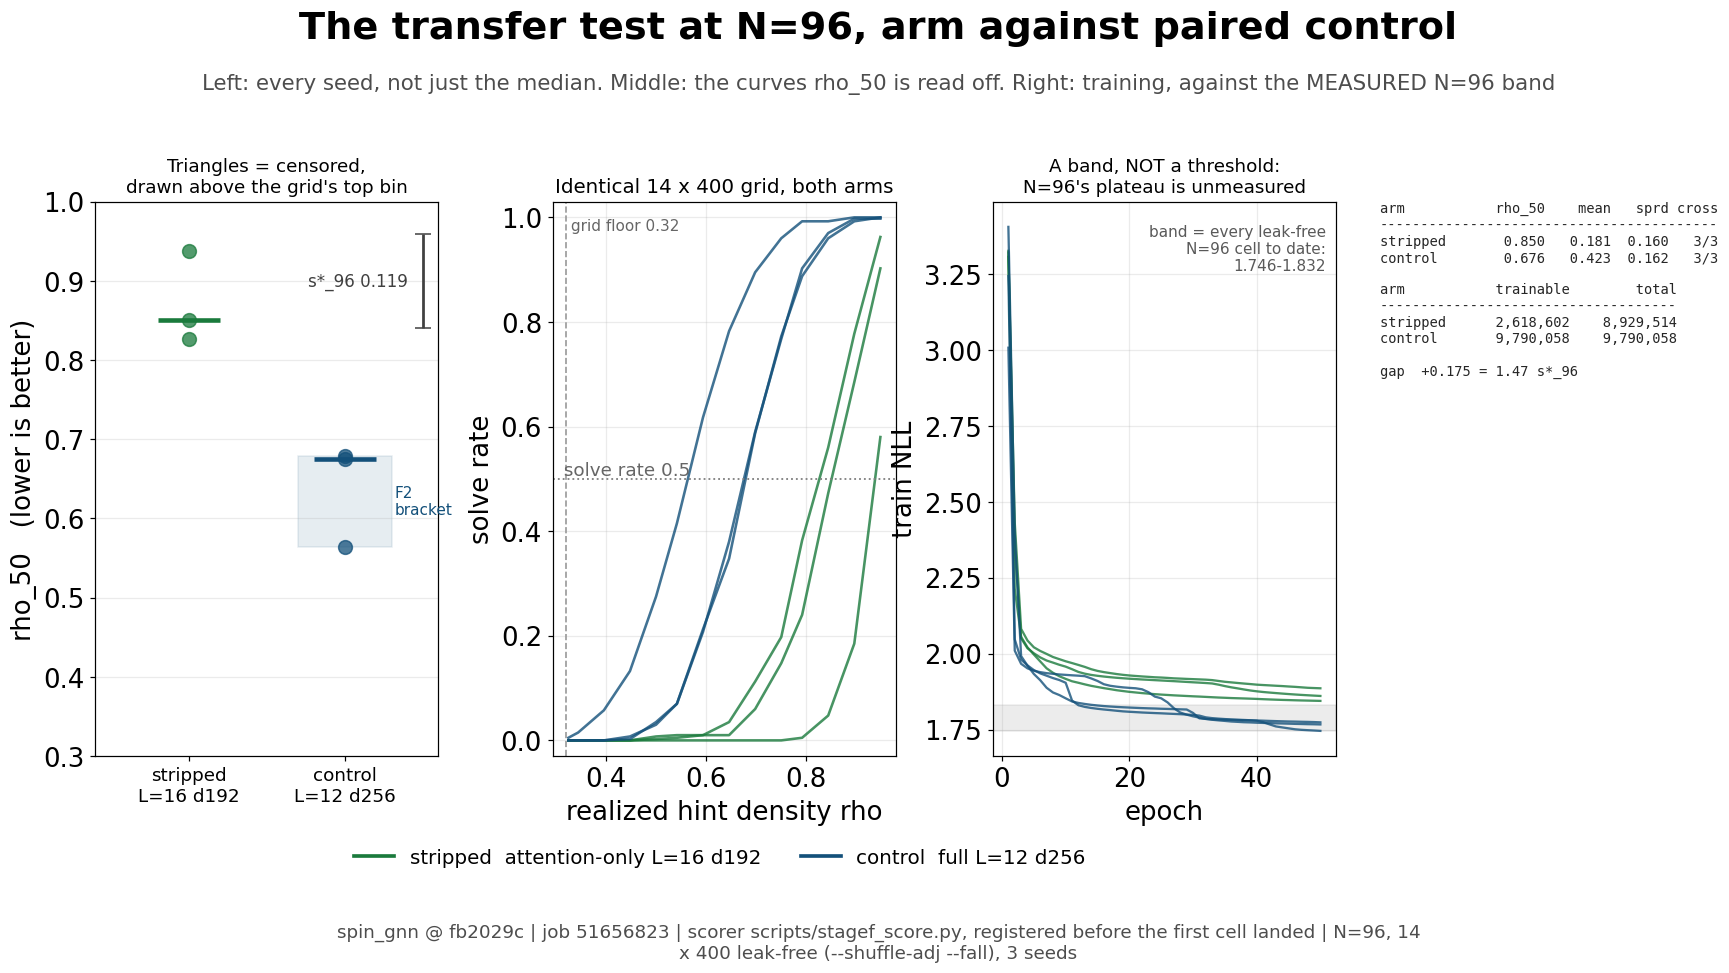

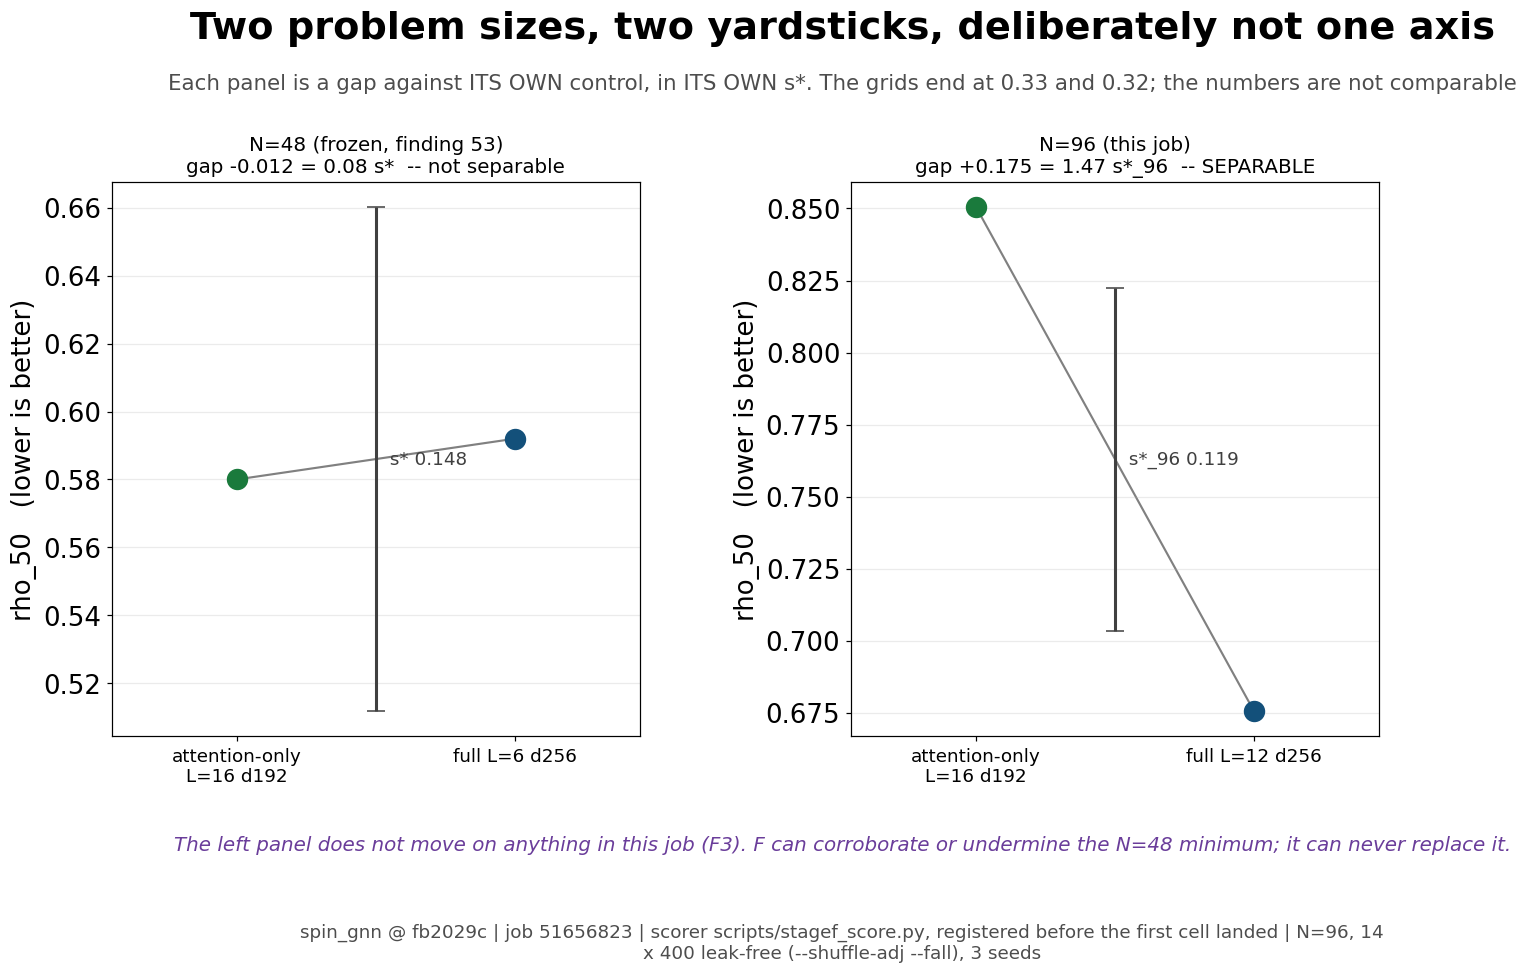

In [6]:
from notebooks.make_stagef_deck import page_contrast, page_two_sizes
from notebooks.deck_utils import set_style

set_style()


class Keep:
    # A PdfAndPng stand-in that keeps the figure open for the notebook.
    def savefig(self, fig):
        pass


page_contrast(Keep(), p, raw, COMMIT)
page_two_sizes(Keep(), p, COMMIT)

## 7. Token accuracy, and the curve that is deliberately NOT applied

The programme's standing sufficiency result is that a cell's mean solve rate is
predicted by its validation token accuracy alone, through a curve fitted on the
**N=48 depth ladder**. It has held through every cut tried so far, which is a
correlational statement about that grid's range.

**It is not applied here, and that is a decision, not an omission.** The curve
maps token accuracy to solve rate at N=48. At N=96 the sequences are longer, the
vocabulary is larger, and the solve task is harder at the same accuracy, so the
mapping is a different function — feeding N=96 accuracies into the N=48 fit
would produce numbers that look like a test and are not one. Building the N=96
version needs an N=96 **depth ladder**, which does not exist; it is several jobs,
not a cell.

What is reportable without a curve is the raw comparison: the two arms' final
validation token accuracy, side by side with their solve levels. If the stripped
arm matches the control on accuracy but not on `rho_50`, that is the signature of
a deduction-specific failure the accuracy channel cannot see — the thing the
sufficiency result says has never happened at N=48 — and it would be the most
interesting outcome in this job.

In [7]:
print(f"{'arm':<34}{'tok acc':>10}{'rho_50':>10}{'mean_solve':>12}"
      f"{'final NLL':>11}")
print("-" * 77)
for tag in ("stripped", "control"):
    a = p[tag]
    if a is None:
        print(f"{tag + '  (absent)':<34}")
        continue
    nlls = [curve(m["path"])[0][-1] for m in a["ms"]]
    med = sorted(nlls)[len(nlls) // 2]
    print(f"{tag + '  ' + a['name']:<34}{a['acc']:>10.4f}{rho_txt(a['s']):>10}"
          f"{a['s']['mean_solve']:>12.3f}{med:>11.4f}")
print()
if p["stripped"] and p["control"]:
    da = p["stripped"]["acc"] - p["control"]["acc"]
    print(f"  accuracy gap  {da:+.4f}")
    if d is not None:
        print(f"  solve gap     {d:+.3f} = {abs(d) / S96:.2f} s*_96")
        print("  Both small -> the arms are matched on both channels. Accuracy matched")
        print("  but solve NOT -> the deduction-specific failure mode, which would be")
        print("  new. Neither reading is asserted here; the numbers above are.")
    else:
        print("  solve gap     n/a -- one arm has no level, so only the accuracy")
        print("  channel is readable and it cannot settle anything on its own.")
print()
lo, hi = CONTROL_NLL_BAND
print(f"  the measured N=96 NLL band is {lo:.4f}-{hi:.4f}. A cell inside it trained")
print("  as well as every leak-free N=96 cell before it; a cell far above it did not")
print("  train, which is a TRAINABILITY reading and not an architecture one. No")
print("  escape count is quoted, because N=96's plateau has never been measured.")

arm                                  tok acc    rho_50  mean_solve  final NLL
-----------------------------------------------------------------------------
stripped  attention-only L=16 d192    0.4709     0.850       0.181     1.8606
control  full L=12 d256               0.4822     0.676       0.423     1.7667

  accuracy gap  -0.0113
  solve gap     +0.175 = 1.47 s*_96
  Both small -> the arms are matched on both channels. Accuracy matched
  but solve NOT -> the deduction-specific failure mode, which would be
  new. Neither reading is asserted here; the numbers above are.

  the measured N=96 NLL band is 1.7456-1.8320. A cell inside it trained
  as well as every leak-free N=96 cell before it; a cell far above it did not
  train, which is a TRAINABILITY reading and not an architecture one. No
  escape count is quoted, because N=96's plateau has never been measured.


## 8. `rho_50` before and after, on the same eval

Two different before/afters are in play here and conflating them is the easiest
mistake to make in this write-up, so they are separated.

**At N=96, which is what this job measures.** The "before" is the control as it
stood at registration: `full L=12 d256`, `rho_50` **0.621** over two seeds, on
this identical 14 × 400 leak-free grid at this identical 240k × 50 budget. The
"after" is the same control at three seeds plus the stripped arm. Both are N=96
numbers measured on the same eval, which is the only pairing in this notebook
where a difference means anything.

**At N=48, which this job does NOT move (F3).** The standing minimum moved on
2026-11-09, from attention-only `L=12 d256` (E2, 3,331,642 trainable @ 0.605,
finding 50, set 2026-11-05) to attention-only `L=16 d192` (J2, 2,504,890 @
0.580, finding 53). **Anything written before 11-09 — including notes and briefs
that quote "0.605 at 3,331,642" as the current standing minimum — is one step
stale.** The correct N=48 "before" for any size-pushing claim is J2's 0.580 at
2,504,890. Stage F can corroborate or undermine it; it cannot replace it, and
nothing in this section does.

In [8]:
desc48, tr48, rho48 = N48_MINIMUM
hdesc, htr, hrho = N48_HUB

print("AT N=96 -- the pairing this job measures, same grid, same budget")
print(f"  {'arm':<40}{'rho_50':>10}{'mean_solve':>12}{'trainable':>12}")
print("  " + "-" * 74)
print(f"  {'BEFORE  control full L=12 d256, 2 seeds':<40}{CONTROL_2SEED:>10.3f}"
      f"{'--':>12}{'--':>12}")
for tag in ("control", "stripped"):
    a = p[tag]
    if a is None:
        print(f"  {('AFTER   ' if tag == 'control' else 'ARM     ') + tag + ' -- no cell on disk':<40}"
              f"{'--':>10}{'--':>12}{'--':>12}")
        continue
    lab = ("AFTER   " if tag == "control" else "ARM     ") + a["name"]
    print(f"  {lab:<40}{rho_txt(a['s']):>10}{a['s']['mean_solve']:>12.3f}"
          f"{a['trainable']:>12,}")
print()
if ct is not None and ct["rho50_readable"]:
    shift = ct["rho50"] - CONTROL_2SEED
    print(f"  the control moved {shift:+.3f} = {abs(shift) / S96:.2f} s*_96 on going "
          f"from 2 seeds to {ct['n']}.")
    print(f"  F2 registered that this shift stays within s*_96; it is "
          f"{'INSIDE' if abs(shift) <= S96 else 'OUTSIDE'}.")
else:
    print("  the control has no readable 3-seed level, so the N=96 'after' is not a")
    print("  level at all and F0 is not scored as one. See section 5.")
print()
print("AT N=48 -- frozen here, quoted so that no number above can be read as moving it")
print(f"  {'rung':<48}{'rho_50':>10}{'trainable':>12}")
print("  " + "-" * 70)
print(f"  {'J2   standing minimum    ' + desc48:<48}{rho48:>10.3f}{tr48:>12,}")
print(f"  {'hub  complete model      ' + hdesc:<48}{hrho:>10.3f}{htr:>12,}")
print(f"  {'E2   superseded 11-09    no_mlp L=12 d256':<48}{0.605:>10.3f}{3331642:>12,}")
print()
print("  F3: these three rows are an N=48 ladder result on a grid whose floor is")
print("  0.33. Stage F's numbers are on a grid whose floor is 0.32. They are never")
print("  pooled, never differenced, and never put on one axis -- see section 6's")
print("  second figure, which draws each size against its own control in its own s*.")

AT N=96 -- the pairing this job measures, same grid, same budget
  arm                                         rho_50  mean_solve   trainable
  --------------------------------------------------------------------------
  BEFORE  control full L=12 d256, 2 seeds      0.621          --          --
  AFTER   full L=12 d256                       0.676       0.423   9,790,058
  ARM     attention-only L=16 d192             0.850       0.181   2,618,602

  the control moved +0.055 = 0.46 s*_96 on going from 2 seeds to 3.
  F2 registered that this shift stays within s*_96; it is INSIDE.

AT N=48 -- frozen here, quoted so that no number above can be read as moving it
  rung                                                rho_50   trainable
  ----------------------------------------------------------------------
  J2   standing minimum    attention-only L=16 d192     0.580   2,504,890
  hub  complete model      full L=6 d256               0.592   4,899,898
  E2   superseded 11-09    no_mlp L=12 d2

## 9. What this does not settle, and what is running

**Two sizes is not a scaling law.** Whatever F found, the claim it can earn is
"the cut is free at N=48 and at N=96", not "the cut is free". A third size — or
better, a size where it breaks — is what would turn two points into a trend, and
nothing in this job says which direction to look. **Treat a breaking point as the
result**: if the stripped arm censors at N=96, where it stops working is a
sharper number than another size where it works.

**N=96's plateau is still unmeasured.** Every trainability reading on these
pages leans on a 1.7456–1.8320 band assembled from eight cells that happen to
exist, not on a measured plateau like finding 44's 1.64 at N=48. A short N=96
depth ladder would fix that and would also be the prerequisite for porting the
token-accuracy sufficiency curve to this size (section 7).

**The open N=48 question is still open and still not bundled here.** The width
curve is convex on [192, 256] at `L=12`: all three registered interpolations
overestimated `rho_50` at `d224` (J1). A fourth width point is the only way to
know the shape of that stretch. It is worth 3 cells and it was queued behind
this job, because stage F decides whether any N=48 number is worth generalizing
in the first place.

**`51668331` stage K** ran alongside this one and asks the N=48 complement:
every rung below ~2M parameters on record is an `L=12` rung, so is the floor the
TASK's or only `L=12`'s? It tests attention-only `L=16` at `d160` and `d128`,
three seeds each. Its verdict is on its own slides, in N=48's own yardstick;
nothing here moves it and nothing there moves anything here.

**What a reader should check first.** The per-seed levels in section 4, not the
medians. Seed spread at a fixed architecture has exceeded the depth gaps
throughout this programme, and `s*_96` = 0.119 is a measured spread rather than
a confidence interval. If a gap on these pages is smaller than that bar, the
reading is "no separable difference" — and no section here says otherwise.